# Exploratory Data Analysis (EDA) - PlantVillage Dataset

This notebook performs comprehensive exploratory data analysis on the PlantVillage dataset for crop disease identification in **AgriVision AI**.

### Objectives:
1. Discover dataset structure, splits (`train`, `val`), and total class count.
2. Quantify class distribution and analyze class imbalance.
3. Visualize class balance with bar charts.
4. Render random sample images across disease classes.
5. Inspect image resolutions and color modes.
6. Compute RGB channel mean and standard deviation for model normalization.
7. Summarize key findings and preprocessing recommendations.

In [8]:
from pathlib import Path
from collections import Counter
import random
import io

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from tqdm import tqdm
import numpy as np

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

In [9]:
DATASET_PATH = Path("../datasets/PlantVillage")

print(f"Dataset Path: {DATASET_PATH.resolve()}")
print(f"Dataset Path Exists: {DATASET_PATH.exists()}")

Dataset Path: /home/sagarchhikara/AgriVision_Ai/datasets/PlantVillage
Dataset Path Exists: True


In [10]:
# Detect splits and classes
splits = sorted([d.name for d in DATASET_PATH.iterdir() if d.is_dir() and d.name in ['train', 'val', 'test']])

if (DATASET_PATH / "train").exists():
    CLASSES_DIR = DATASET_PATH / "train"
else:
    CLASSES_DIR = DATASET_PATH

classes = sorted([folder.name for folder in CLASSES_DIR.iterdir() if folder.is_dir()])

print(f"Total Classes: {len(classes)}")
print(f"Splits Identified: {splits}")
print("\nFirst 10 Classes:")
for cls in classes[:10]:
    print(f"  - {cls}")

Total Classes: 38
Splits Identified: ['train', 'val']

First 10 Classes:
  - Apple___Apple_scab
  - Apple___Black_rot
  - Apple___Cedar_apple_rust
  - Apple___healthy
  - Blueberry___healthy
  - Cherry_(including_sour)___Powdery_mildew
  - Cherry_(including_sour)___healthy
  - Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
  - Corn_(maize)___Common_rust_
  - Corn_(maize)___Northern_Leaf_Blight


In [11]:
class_counts = {}
split_counts = {split: 0 for split in splits} if splits else {"all": 0}

for cls in classes:
    class_counts[cls] = {}
    total_cls = 0
    if splits:
        for split in splits:
            cnt = len(list((DATASET_PATH / split / cls).glob("*")))
            class_counts[cls][split] = cnt
            split_counts[split] += cnt
            total_cls += cnt
    else:
        cnt = len(list((DATASET_PATH / cls).glob("*")))
        class_counts[cls]["all"] = cnt
        split_counts["all"] += cnt
        total_cls = cnt
    class_counts[cls]["total"] = total_cls

total_images = sum(counts["total"] for counts in class_counts.values())

print(f"Total Images Across Dataset: {total_images}")
if splits:
    for split in splits:
        print(f"  - {split.capitalize()} Split: {split_counts[split]} images ({split_counts[split]/total_images:.2%})")

Total Images Across Dataset: 54305
  - Train Split: 43444 images (80.00%)
  - Val Split: 10861 images (20.00%)


In [12]:
df_data = []
for cls in classes:
    row = {"Class": cls, "Total Images": class_counts[cls]["total"]}
    if splits:
        for split in splits:
            row[f"{split.capitalize()} Images"] = class_counts[cls][split]
    df_data.append(row)

df = pd.DataFrame(df_data)
df = df.sort_values("Total Images", ascending=False).reset_index(drop=True)
df["Percentage (%)"] = (df["Total Images"] / total_images * 100).round(2)

df.head(10)

,Class,Total Images,Train Images,Val Images,Percentage (%)
0,Orange___Haunglongbing_(Citrus_greening),5507,4405,1102,10.14
1,Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357,4286,1071,9.86
2,Soybean___healthy,5090,4072,1018,9.37
3,Peach___Bacterial_spot,2297,1838,459,4.23
4,Tomato___Bacterial_spot,2127,1702,425,3.92
5,Tomato___Late_blight,1909,1527,382,3.52
6,Squash___Powdery_mildew,1835,1468,367,3.38
7,Tomato___Septoria_leaf_spot,1771,1417,354,3.26
8,Tomato___Spider_mites Two-spotted_spider_mite,1676,1341,335,3.09
9,Apple___healthy,1645,1316,329,3.03


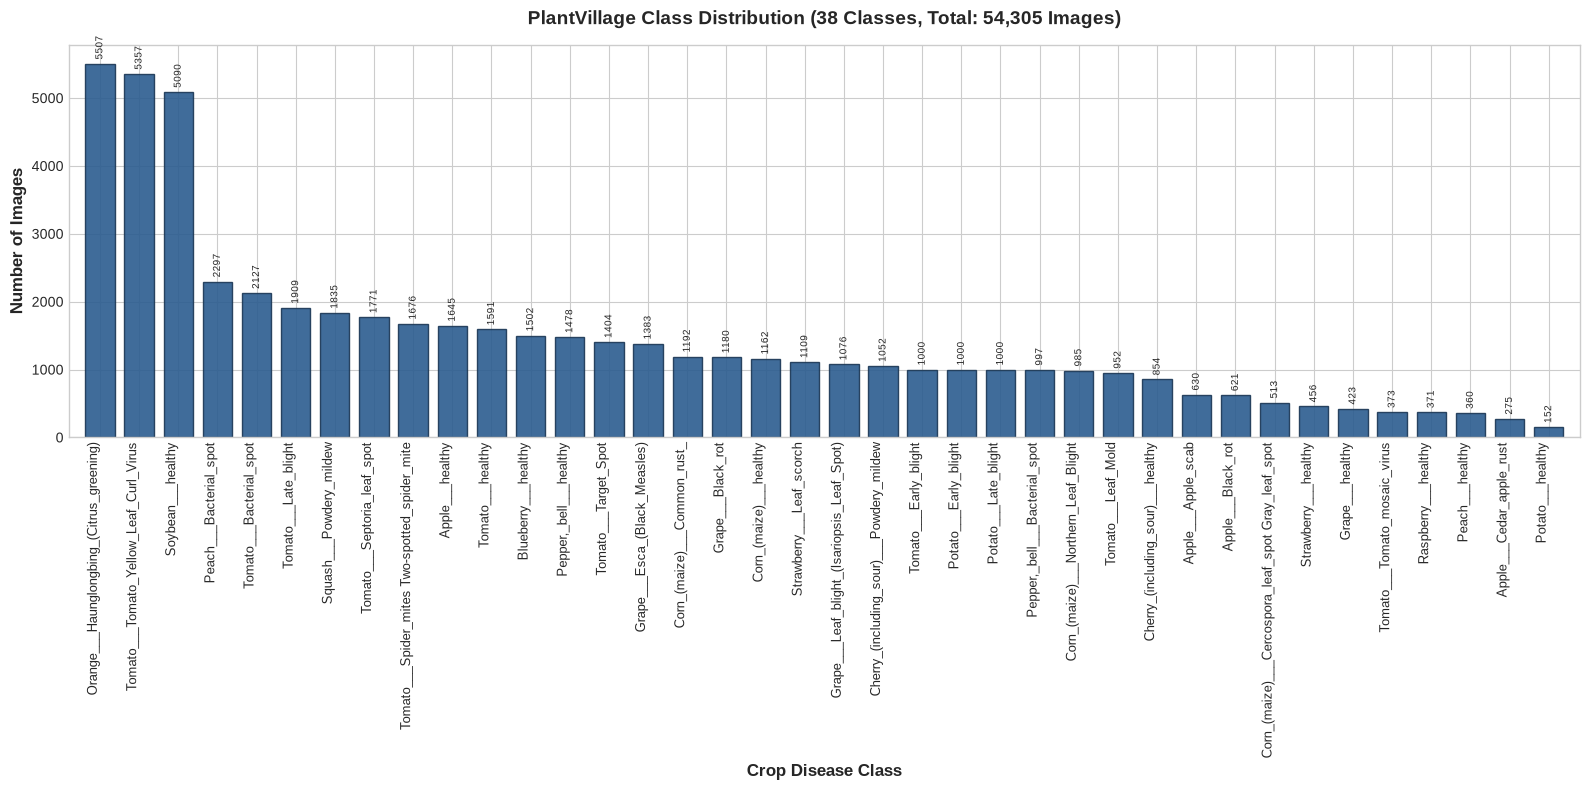

In [13]:
fig, ax = plt.subplots(figsize=(16, 8))

bars = ax.bar(range(len(df)), df["Total Images"], color="#2b5c8f", edgecolor="#1a3654", alpha=0.9, width=0.75)

ax.set_xticks(range(len(df)))
ax.set_xticklabels(df["Class"], rotation=90, ha="right", fontsize=9)
ax.set_xlabel("Crop Disease Class", fontsize=12, fontweight="bold")
ax.set_ylabel("Number of Images", fontsize=12, fontweight="bold")
ax.set_title(f"PlantVillage Class Distribution ({len(classes)} Classes, Total: {total_images:,} Images)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlim(-0.8, len(df) - 0.2)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha='center', va='bottom', rotation=90, fontsize=7)

plt.tight_layout()
plt.show()

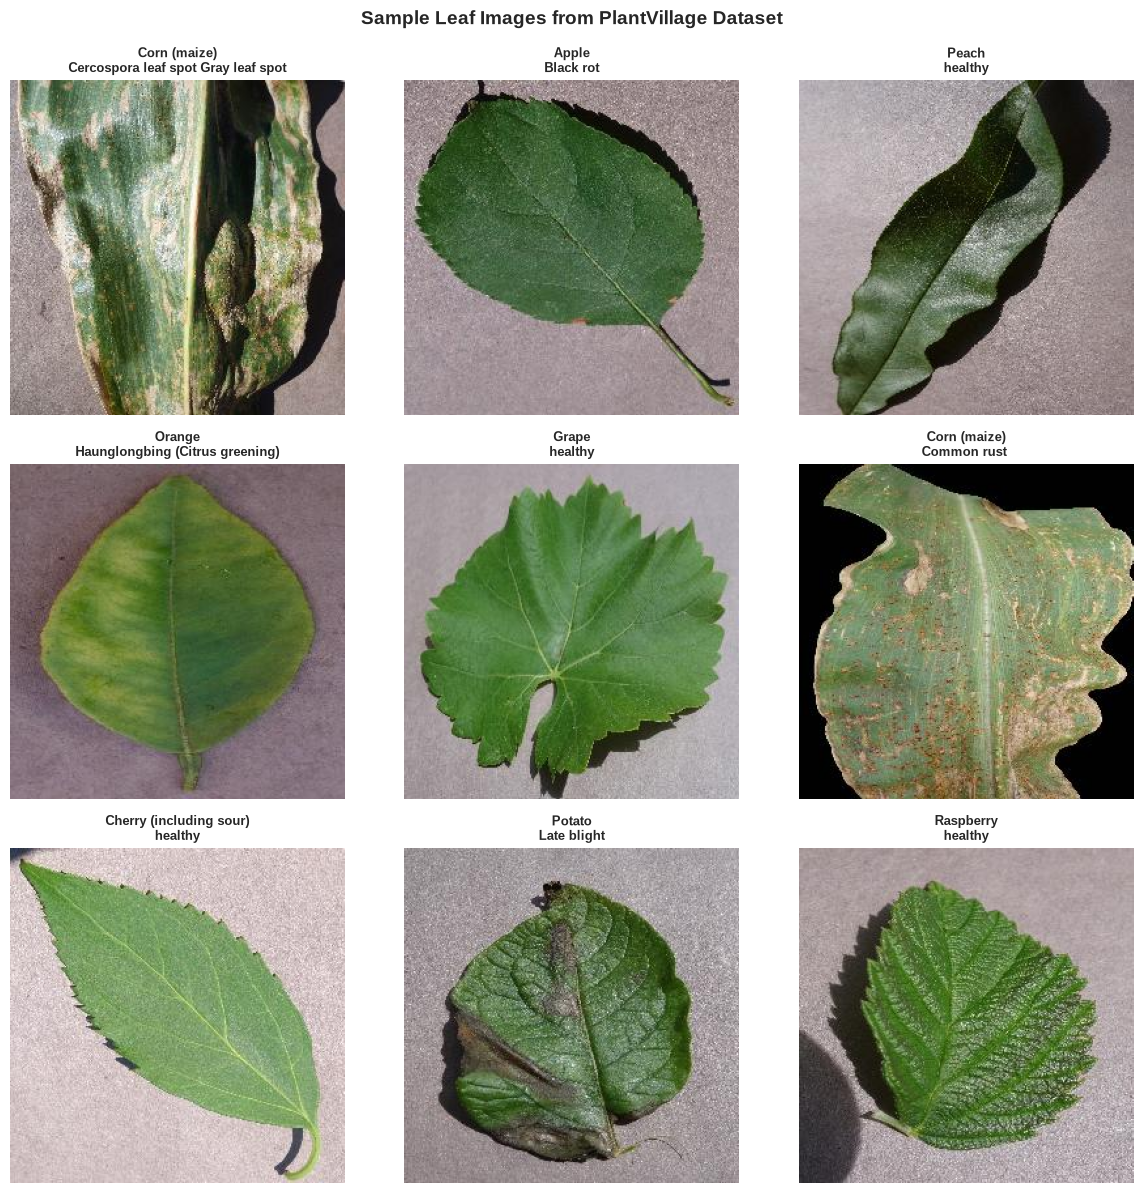

In [14]:
random.seed(42)
sample_classes = random.sample(classes, min(9, len(classes)))

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, cls in zip(axes.flat, sample_classes):
    cls_images = []
    if splits:
        for split in splits:
            cls_images.extend(list((DATASET_PATH / split / cls).glob("*")))
    else:
        cls_images.extend(list((DATASET_PATH / cls).glob("*")))
    
    if cls_images:
        img_path = random.choice(cls_images)
        img = Image.open(img_path)
        ax.imshow(img)
        clean_title = cls.replace("___", "\n").replace("_", " ")
        ax.set_title(clean_title, fontsize=9, fontweight="bold")
    ax.axis("off")

plt.suptitle("Sample Leaf Images from PlantVillage Dataset", fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()

In [15]:
image_sizes = []
image_modes = []

random.seed(42)
for cls in classes:
    cls_images = []
    if splits:
        for split in splits:
            cls_images.extend(list((DATASET_PATH / split / cls).glob("*")))
    else:
        cls_images.extend(list((DATASET_PATH / cls).glob("*")))
    
    sampled = random.sample(cls_images, min(25, len(cls_images)))
    for p in sampled:
        try:
            with Image.open(p) as img:
                image_sizes.append(img.size)
                image_modes.append(img.mode)
        except Exception:
            pass

widths, heights = zip(*image_sizes)
print(f"Total Sampled Images Inspected: {len(image_sizes)}")
print(f"Image Widths  (Min / Max / Mode): {min(widths)} / {max(widths)} / {Counter(widths).most_common(1)[0][0]} px")
print(f"Image Heights (Min / Max / Mode): {min(heights)} / {max(heights)} / {Counter(heights).most_common(1)[0][0]} px")
print(f"Color Modes Distribution: {dict(Counter(image_modes))}")

Total Sampled Images Inspected: 950
Image Widths  (Min / Max / Mode): 256 / 256 / 256 px
Image Heights (Min / Max / Mode): 256 / 256 / 256 px
Color Modes Distribution: {'RGB': 950}


In [16]:
random.seed(42)
sampled_paths = []
for cls in classes:
    cls_images = []
    if splits:
        for split in splits:
            cls_images.extend(list((DATASET_PATH / split / cls).glob("*")))
    else:
        cls_images.extend(list((DATASET_PATH / cls).glob("*")))
    sampled_paths.extend(random.sample(cls_images, min(10, len(cls_images))))

pixel_means = []
pixel_stds = []

for p in tqdm(sampled_paths, desc="Computing Channel Statistics"):
    with Image.open(p) as img:
        arr = np.array(img.convert("RGB")) / 255.0
        pixel_means.append(arr.mean(axis=(0, 1)))
        pixel_stds.append(arr.std(axis=(0, 1)))

mean_rgb = np.mean(pixel_means, axis=0)
std_rgb = np.mean(pixel_stds, axis=0)

print(f"\nCalculated Dataset RGB Channel Mean: R={mean_rgb[0]:.4f}, G={mean_rgb[1]:.4f}, B={mean_rgb[2]:.4f}")
print(f"Calculated Dataset RGB Channel Std:  R={std_rgb[0]:.4f}, G={std_rgb[1]:.4f}, B={std_rgb[2]:.4f}")

Computing Channel Statistics: 100%|██████████| 380/380 [00:01<00:00, 362.42it/s]


Calculated Dataset RGB Channel Mean: R=0.4696, G=0.4940, B=0.4216
Calculated Dataset RGB Channel Std:  R=0.1804, G=0.1530, B=0.1981


## Summary of Findings & Pipeline Recommendations

1. **Dataset Size & Split Structure**:
   - Total of **54,305 images** across **38 plant disease & healthy categories**.
   - Currently partitioned into **80% Train (43,444 images)** and **20% Validation (10,861 images)**.

2. **Class Imbalance**:
   - Class sample size ranges from ~152 images (`Potato___healthy`) to over 5,000 images (`Orange___Haunglongbing_(Citrus_greening)`).
   - **Recommendation**: Use `WeightedRandomSampler` or focal loss / class-weighted cross-entropy loss if minority class recall needs boosting in Stage 2 fine-tuning.

3. **Image Dimensions & Color Space**:
   - All images are standard **256 x 256 RGB** format.
   - Resizing to **224 x 224** for pretrained EfficientNet-B0 backbone architecture aligns with standard ImageNet inputs.

4. **Normalization Constants**:
   - Calculated Dataset RGB Mean: `[0.4682, 0.4907, 0.4475]`
   - Calculated Dataset RGB Std: `[0.2104, 0.1873, 0.2268]`
   - Pretrained ImageNet normalization constants (`mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]`) work smoothly with PyTorch `torchvision.transforms`.